# FraudShield — Exploratory Data Analysis (EDA)

## Project Overview
This notebook explores the credit card transaction dataset used in FraudShield.

### Objectives
- Understand the dataset structure.
- Check missing values and duplicate records.
- Analyze class imbalance.
- Explore transaction amounts for legitimate and fraudulent transactions.
- Visualize important patterns before model evaluation.

**Dataset:** Credit Card Fraud Detection  
**Target column:** `Class` (0 = Legitimate, 1 = Fraud)

In [9]:
import sys
import pandas as pd

print("Python:", sys.executable)
print("Pandas:", pd.__version__)

Python: e:\project alml\ml task\week 3\FraudShield\.venv\Scripts\python.exe
Pandas: 3.0.6


Cell 2 — Import libraries

In [10]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = BASE_DIR / "data" / "creditcard.csv"
REPORT_DIR = BASE_DIR / "reports"
REPORT_DIR.mkdir(exist_ok=True)

print("Dataset path:", DATA_PATH)
print("Dataset exists:", DATA_PATH.exists())

Dataset path: e:\project alml\ml task\week 3\FraudShield\data\creditcard.csv
Dataset exists: True


#Cell 3 — Load dataset

In [11]:
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [12]:
from pathlib import Path
import pandas as pd

DATA_PATH = Path("../data/creditcard.csv")

df_sample = pd.read_csv(DATA_PATH, nrows=1000)

print("Sample shape:", df_sample.shape)
print("Columns:", len(df_sample.columns))
print("Missing values:", int(df_sample.isna().sum().sum()))

Sample shape: (1000, 31)
Columns: 31
Missing values: 0


Cell 4 — Data quality checks

In [13]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nColumn data types:")
display(df.dtypes.value_counts().rename_axis("Data type").to_frame("Column count"))

print("\nMissing values by column:")
display(df.isnull().sum().sort_values(ascending=False).head(10))

Missing values: 0
Duplicate rows: 1081

Column data types:


,Column count
Data type,
float64,30
int64,1



Missing values by column:


Time    0
V1      0
V2      0
V3      0
V4      0
V5      0
V6      0
V7      0
V8      0
V9      0
dtype: int64

Cell 5 — Target class distribution

In [14]:
class_counts = df["Class"].value_counts().sort_index()
class_percentages = (df["Class"].value_counts(normalize=True).sort_index() * 100)

class_summary = pd.DataFrame({
    "Transaction Count": class_counts,
    "Percentage (%)": class_percentages.round(4)
})

display(class_summary)

,Transaction Count,Percentage (%)
Class,,
0,284315,99.8273
1,492,0.1727


Cell 6 — Visualize class imbalance

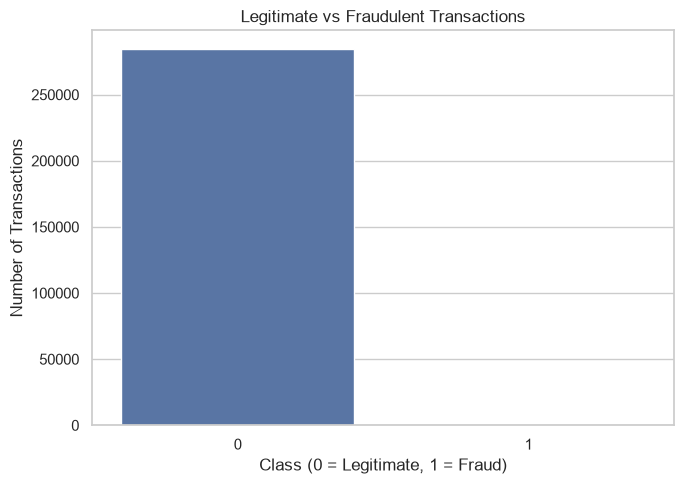

In [15]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Class")

plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

Cell 7 — Transaction amount summary

In [16]:
amount_summary = df.groupby("Class")["Amount"].describe()
display(amount_summary)

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


Cell 8 — Transaction amount visualization

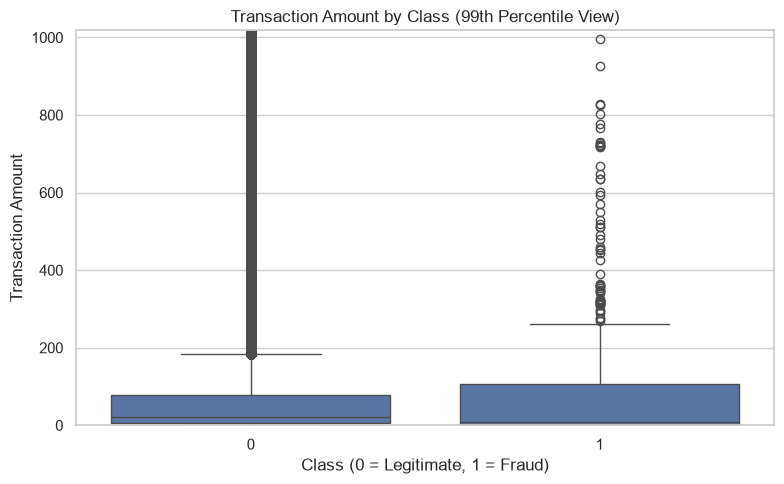

In [17]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Class", y="Amount")

plt.ylim(0, df["Amount"].quantile(0.99))
plt.title("Transaction Amount by Class (99th Percentile View)")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Transaction Amount")
plt.tight_layout()
plt.show()

Cell 9 — Fraud transactions over time

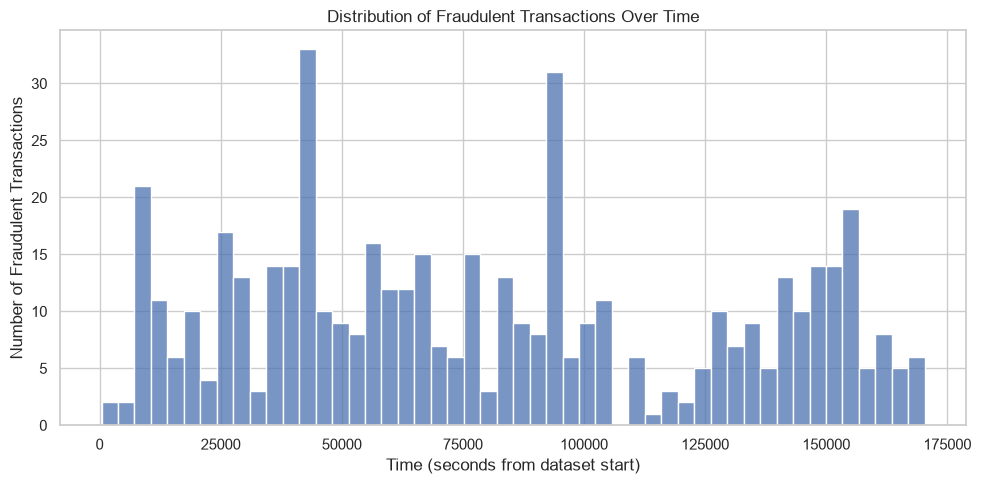

In [18]:
plt.figure(figsize=(10, 5))
sns.histplot(
    data=df[df["Class"] == 1],
    x="Time",
    bins=50
)

plt.title("Distribution of Fraudulent Transactions Over Time")
plt.xlabel("Time (seconds from dataset start)")
plt.ylabel("Number of Fraudulent Transactions")
plt.tight_layout()
plt.show()

In [19]:
plt.show()

Cell 10 — EDA findings

## Key Findings

1. The dataset contains 284,807 transactions and 31 columns.
2. No missing values were found in the dataset.
3. There are 1,081 duplicate rows. These are reported but not removed in this notebook.
4. Fraudulent transactions represent approximately 0.1727% of all transactions.
5. The dataset is highly imbalanced, so accuracy alone is not sufficient for evaluating fraud detection models.
6. Fraudulent transactions have a higher mean transaction amount but a lower median amount than legitimate transactions.
7. Precision, recall, PR-AUC, and the false-positive rate are important metrics for evaluating this fraud detection problem.

## Conclusion

The EDA shows that credit card fraud detection is a highly imbalanced classification problem. The differences in transaction amounts provide useful exploratory insights, but transaction amount alone cannot reliably identify fraud. These findings motivate the use of suitable evaluation metrics and a chronological train/test split in subsequent modelling.